# <font color = "red">**Day 24: Physics-Informed Learning from Atomic-Resolution Microscopy**</font>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kbarakati/athena_camm_hackathon/blob/k4my4r/docs/day_24_11062026/reward_driven_image_analysis.ipynb)

**Challenge Overview**

Atomic-resolution scanning transmission electron microscopy (STEM) provides detailed information about the local structure of crystalline materials. However, extracting physically meaningful properties from microscopy images often requires specialized analysis, atomic-scale measurements, and knowledge of the underlying material structure.

**<font color = "blue">The goal of this challenge is to develop physics-informed algorithms that extract local material properties directly from high-angle annular dark-field (HAADF-STEM) images.</font>**

Participants will work with atomic-resolution images of Sm-doped BiFeO₃ (Sm-BFO) at different compositions (0%, 7%, 10%, 13%, and 20% Sm). 

- The primary objective is to reconstruct spatial maps of local polarization-related atomic displacements using image analysis, machine learning, or physics-guided computational methods.

**Participants may use:**

1. HAADF images: Raw atomic-resolution microscopy images.

2. Atomic coordinates (xy_atms): Positions of detected atomic columns.

3. Unit-cell coordinates (xy_COM): Reference positions associated with individual unit cells.

4. Structural parameters: Lattice parameters, unit-cell geometry, and other non-target structural descriptors.

5. Material information: Sm composition and relevant crystallographic knowledge.

Participants may combine these inputs with physical models, computer vision, statistical methods, or machine learning to reconstruct local material properties.

<font color = "red">**Ground Truth and Restrictions**</font>

Reference polarization-related displacement maps **(Pxy)** are provided for verification and evaluation only.

- Participants must not use these reference values as inputs to their algorithms, for model training, or for selecting and optimizing model parameters.

- The reference data may only be used after generating predictions to evaluate the agreement between reconstructed and reference maps.

- Any additional property used as an input must not directly encode or reproduce the reference polarization values.

### load data

In [1]:
import os
import h5py
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
! gdown --folder "https://drive.google.com/drive/folders/1fXwChjwMT9PH5YtonZoDG3kXVL6mfEQg?usp=sharing"

In [3]:
#list files
filedir = 'data_small'
[f for f in os.listdir(filedir)]

['Copy of Sm_0_1_UCParameterization.h5',
 'Copy of Sm_10_1_UCParameterization.h5',
 'Copy of Sm_13_1_HAADF.h5',
 'Copy of Sm_0_1_HAADF.h5',
 'Copy of Sm_13_1_UCParameterization.h5',
 'Copy of Sm_7_3_UCParameterization.h5',
 'Copy of Sm_20_1_UCParameterization.h5',
 'Copy of Sm_20_1_HAADF.h5',
 'Copy of Sm_10_1_HAADF.h5',
 'Copy of Sm_7_3_HAADF.h5']

In [7]:
# Find HAADF images
img_filename = sorted(
    f for f in os.listdir(filedir) if f.endswith("_HAADF.h5")
)

# Match parameterization files
UCparam_filename = [
    f.replace("_HAADF.h5", "_UCParameterization.h5")
    for f in img_filename
]

# Extract Sm composition (%)
composition_tags = [
    int(f.replace("Copy of ", "").split("_")[1])
    for f in img_filename
]

# Load datasets
imgdata = [
    np.asarray(h5py.File(os.path.join(filedir, f), "r")["MainImage"])
    for f in img_filename
]

UCparam = [
    h5py.File(os.path.join(filedir, f), "r")
    for f in UCparam_filename
]

imnum = len(imgdata)

print(f"Loaded {imnum} images and parameterization files")
print("Sm compositions (%):", composition_tags)
print("UC parameters:", list(UCparam[0].keys()))


Loaded 5 images and parameterization files
Sm compositions (%): [0, 10, 13, 20, 7]
UC parameters: ['I1', 'I2', 'I3', 'I4', 'I5', 'NCOM', 'PCOM', 'Pxy', 'Vol', 'a', 'ab', 'abdelta', 'alpha', 'atmindex', 'b', 'index', 'meanuca', 'meanucb', 'nbrUC', 'xy_COM', 'xy_atms']


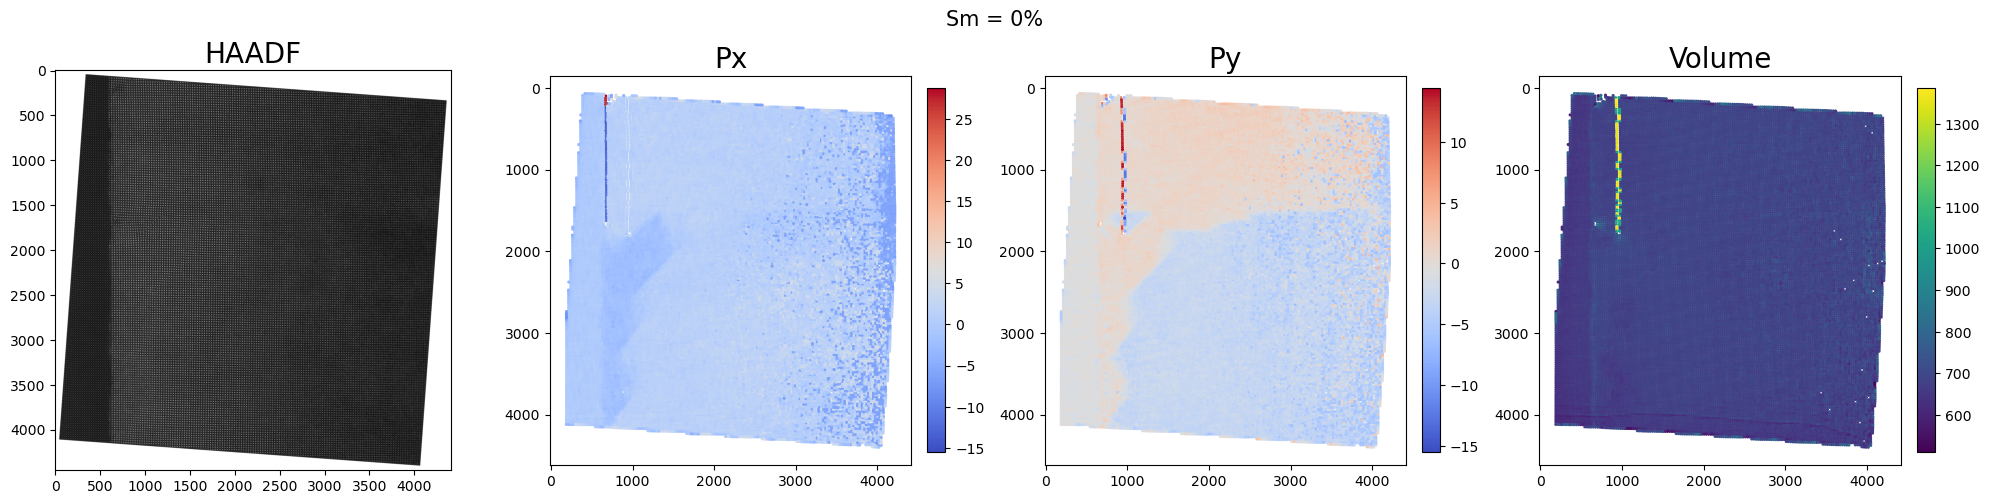

In [24]:
idx = 0

# Load data
img = np.asarray(imgdata[idx]).squeeze()
pxy = np.asarray(UCparam[idx]["Pxy"]).T
vol = np.asarray(UCparam[idx]["Vol"]).ravel()
xy = np.asarray(UCparam[idx]["xy_COM"]).T

# Extract polarization components
px, py = pxy[:, 0], pxy[:, 1]

# Plot HAADF and unit-cell parameters
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

axes[0].imshow(img, cmap="gray")
axes[0].set_title("HAADF", fontsize =20)

for ax, data, title, cmap in zip(
    axes[1:],
    [px, py, vol],
    ["Px", "Py", "Volume"],
    ["coolwarm", "coolwarm", "viridis"]
):
    im = ax.scatter(
        xy[:, 1], xy[:, 0],
        c=data, cmap=cmap, s=5, marker="o", linewidths=0
    )
    ax.invert_yaxis()
    ax.set_title(title, fontsize =20)
    ax.set_aspect("equal")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

# for ax in axes:
#     ax.axis("off")

fig.suptitle(f"Sm = {composition_tags[idx]}%", fontsize=15)
plt.tight_layout()
plt.show()


<font color = "red">**Look Closer**</font>

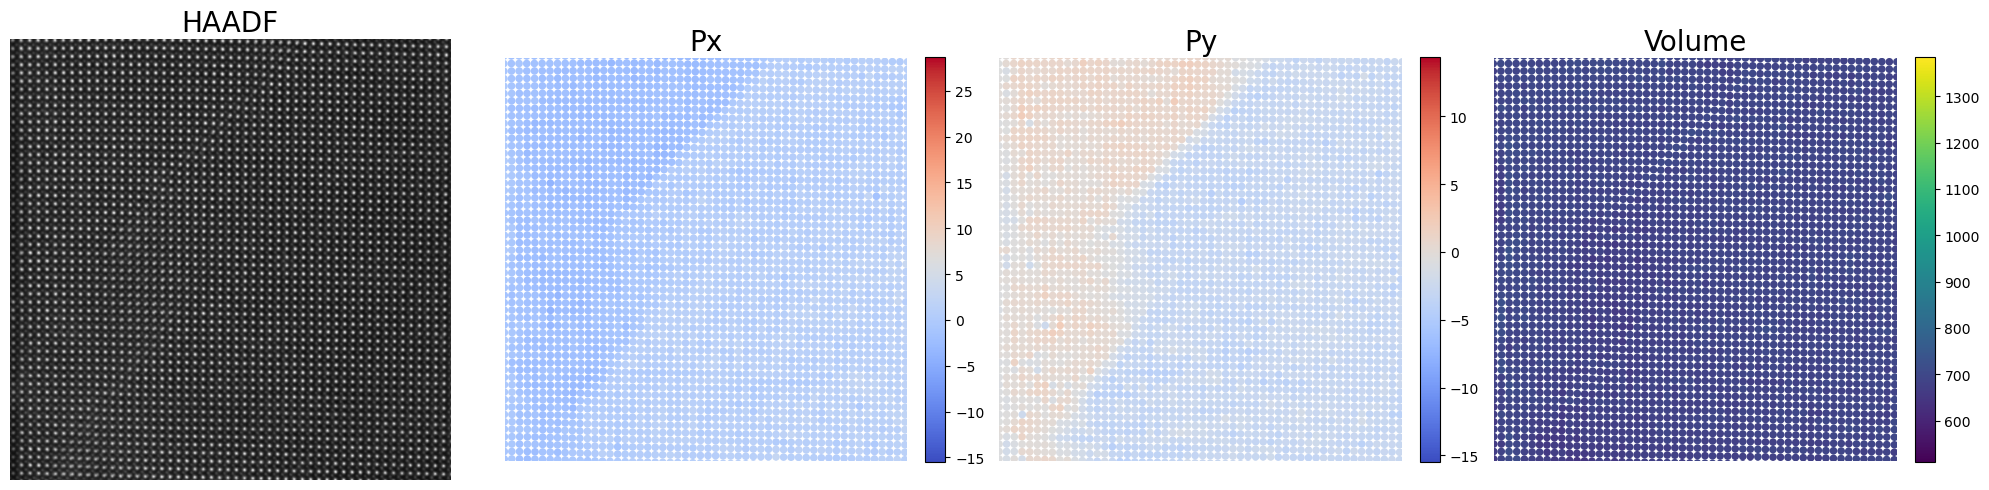

In [25]:
# Select region (image pixel coordinates)
xlim = (600, 2000)
ylim = (2000, 3400)

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

axes[0].imshow(img, cmap="gray")
axes[0].set_title("HAADF", fontsize = 20)

for ax, data, title, cmap in zip(
    axes[1:],
    [px, py, vol],
    ["Px", "Py", "Volume"],
    ["coolwarm", "coolwarm", "viridis"]
):
    im = ax.scatter(
        xy[:, 1], xy[:, 0],
        c=data, cmap=cmap, s=30, marker="o", linewidths=0
    )
    ax.set_title(title, fontsize = 20)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

for ax in axes:
    ax.set_xlim(*xlim)
    ax.set_ylim(ylim[1], ylim[0])
    ax.set_aspect("equal")
    ax.axis("off")

plt.tight_layout()
plt.show()


<font color = "red">**atom cordinates and center of the mass**</font>

Original shape: (2, 5, 23541)


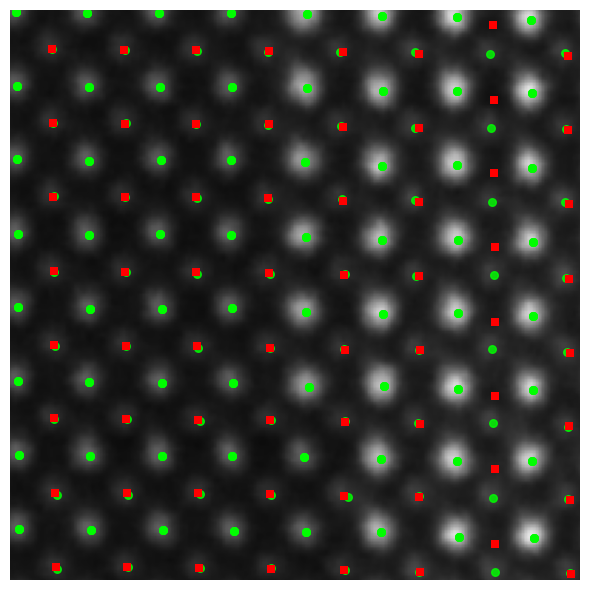

In [26]:
xlim = (500, 700)
ylim = (500, 700)

xy_atms = np.asarray(UCparam[idx]["xy_atms"]).squeeze()

xy = np.asarray(UCparam[idx]["xy_COM"]).T

print("Original shape:", xy_atms.shape)

# Convert coordinates into (N, 2)
if xy_atms.shape[-1] == 2:
    coords = xy_atms.reshape(-1, 2)
elif xy_atms.shape[0] == 2:
    coords = xy_atms.reshape(2, -1).T
else:
    raise ValueError("Inspect xy_atms structure before plotting")

fig, ax = plt.subplots(figsize=(6, 6))

ax.imshow(img, cmap="gray")

ax.scatter(
    coords[:, 1], coords[:, 0],
    s=30, c="lime", alpha=0.8
)

ax.scatter(
    xy[:, 1], xy[:, 0],
    s=30, c="red", marker="s", linewidths=0
)

ax.set_xlim(*xlim)
ax.set_ylim(ylim[1], ylim[0])
ax.set_aspect("equal")
ax.axis("off")

plt.tight_layout()
plt.show()

<font color = "red">**Unit cell**</font>

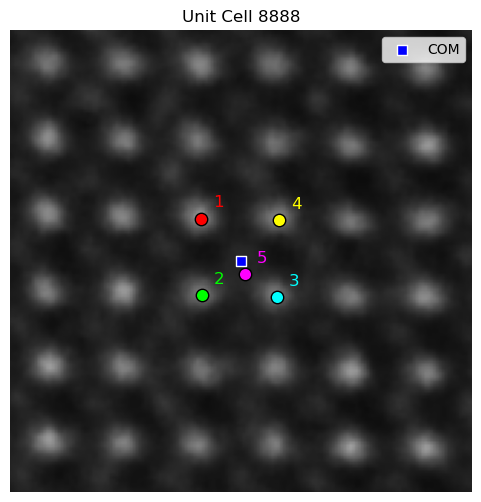

In [27]:
cell = 8888

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(img, cmap="gray")

colors = ["red", "lime", "cyan", "yellow", "magenta"]
atoms = np.asarray(UCparam[idx]["xy_atms"])
com = np.asarray(UCparam[idx]["xy_COM"])

# Plot five atomic positions
for i in range(5):
    y, x = atoms[:, i, cell]
    ax.scatter(x, y, s=80, c=colors[i], edgecolors="black")
    ax.text(x + 4, y - 4, str(i + 1), color=colors[i], fontsize=12)

# Plot center of mass
y_com, x_com = com[:, cell]
ax.scatter(x_com, y_com, s=60, c="blue",
           marker="s", edgecolors="white", label="COM")

# Zoom around the unit cell
x_center = atoms[1, :, cell].mean()
y_center = atoms[0, :, cell].mean()

ax.set_xlim(x_center - 80, x_center + 80)
ax.set_ylim(y_center + 80, y_center - 80)
ax.set_title(f"Unit Cell {cell}")
ax.legend()
ax.set_axis_off()

plt.show()

<font color = "red">**Polarization**</font>

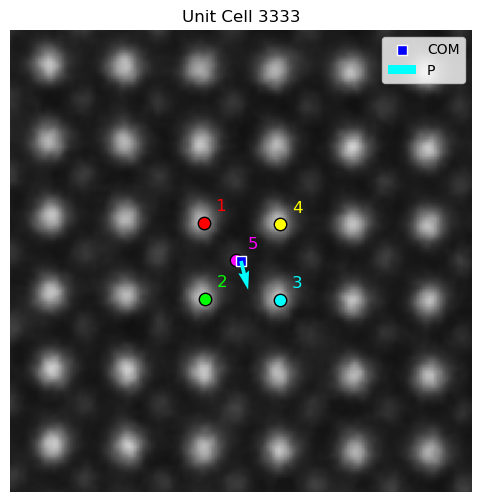

In [30]:
cell = 3333

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(img, cmap="gray")

colors = ["red", "lime", "cyan", "yellow", "magenta"]
atoms = np.asarray(UCparam[idx]["xy_atms"])
com = np.asarray(UCparam[idx]["xy_COM"])
pxy = np.asarray(UCparam[idx]["Pxy"])

# Plot five atomic positions
for i in range(5):
    y, x = atoms[:, i, cell]
    ax.scatter(x, y, s=80, c=colors[i], edgecolors="black")
    ax.text(x + 4, y - 4, str(i + 1), color=colors[i], fontsize=12)

# Plot center of mass
y_com, x_com = com[:, cell]
ax.scatter(x_com, y_com, s=60, c="blue",
           marker="s", edgecolors="white", label="COM")

# Plot polarization components
px, py = pxy[:, cell]

scale = 5  # Arrow magnification
ax.quiver(
    x_com, y_com,
    px * scale, py * scale,
    color="cyan",
    angles="xy", scale_units="xy", scale=1,
    width=0.008, label="P"
)

# Zoom
x_center = atoms[1, :, cell].mean()
y_center = atoms[0, :, cell].mean()

ax.set_xlim(x_center - 80, x_center + 80)
ax.set_ylim(y_center + 80, y_center - 80)
ax.set_aspect("equal")
ax.set_title(f"Unit Cell {cell}")
ax.legend()
ax.set_axis_off()

plt.show()

<font color = "tomato">**Challenge Objectives**</font>

The primary task is to reconstruct the two in-plane components of the local polarization proxy, $P_x$ and $P_y$, and generate spatial maps showing their magnitude and direction.

Participants are encouraged to explore different approaches, including:

- Physics-informed analysis: Use atomic positions, local symmetry, and lattice distortions to estimate polarization-related displacements.

- Computer vision and machine learning: Develop methods to identify structural features and predict local properties from microscopy images.

- Advanced or hybrid approaches: Combine physical constraints, statistical modeling, and learned representations to improve the robustness and accuracy of reconstruction.

<font color = "plum">**Important**</font>
* Participants may also investigate additional properties, such as lattice distortion, local strain, structural heterogeneity, or domain boundaries.

<font color = "navy">**Expected Outcomes**</font>

Participants should submit:

- A reproducible Python workflow or Jupyter notebook.

- Reconstructed spatial maps of $P_x$, $P_y$, and polarization-proxy magnitude or orientation.

- Quantitative comparison with the provided reference maps.

- A short explanation of the physical assumptions, methodology, and limitations.

<font color = "magenta">**Central Scientific Question**</font>


Can we develop physics-informed computational methods that reconstruct local polarization-related properties from atomic-resolution microscopy data without relying on precomputed polarization labels?